# 5.3 Informed Methods

**Informed methods** use **explicit knowledge of the target variable or prediction errors** to detect concept drift.
Unlike “blind” approaches that assume change and retrain regularly, informed methods rely on performance feedback, e.g., monitoring accuracy, error rates, or statistical tests comparing predicted and actual outcomes.
Because they use label information, informed methods can more precisely identify when and where a model’s behavior degrades, helping to distinguish random fluctuations from true drift in the underlying data relationship. However, they continuously require true labels.

In [ ]:
from pathlib import Path

candidate_paths = [
  Path("configs/visualisations.mplstyle"),
  Path("05_Solution_5/configs/visualisations.mplstyle"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find configs/visualisations.mplstyle. Start Jupyter in the repository root or 05_Solution_5.")

print(f"Loading: {data_path.resolve()}")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from src.data_handling import _load_NASA_data
plt.style.use(str(data_path.resolve()))
from src.visual_helper import defined_colors

df = _load_NASA_data()

In [3]:
# select the variables for the analysis
disaster_type = "Flood"
features = ["Total Deaths", "No Injured"]
target = "Total Damages (US$)"

# prepare the data for modeling
df_model = df[df["Disaster Type"] == disaster_type].copy()
df_model = df_model[["Year"] + features + [target]].dropna()

# log-transform features and target to reduce spread (log1p is a robust log-transformation, using the natural logarithm of 1 + x)
df_model = df_model[df_model[target] > 0]
for col in features + [target]:
  df_model[col + " (log)"] = np.log1p(df_model[col])
df_model = df_model.sort_values("Year")

## **TASK: Visualizing Feature Distributions Over Time**

Visualize how features change over time using rolling statistics. Calculate the rolling mean and standard deviation for the number of injured people (logged feature ``No Injured (log)``) using a window size of 30 periods. Plot these rolling statistics alongside the original feature values to observe trends and variations over time. Then, define drift detection thresholds at ±20% of the initial rolling mean value.

Complete the following steps by replacing the ``None`` placeholders with the correct values and variables:
1. Calculate rolling mean and standard deviation for logged feature (Use the pandas method "Rolling": https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.rolling.html)
2. Plot the rolling mean and std deviation over time alongside the original feature values
3. Define drift detection thresholds at ±20% of the initial rolling mean value and visualize them on the plot

In [4]:
# Define rolling window parameters
feature_col = "No Injured (log)" 
window_size = 30 

In [5]:
# (1.) Calculate rolling mean and standard deviation
# ---- YOUR CODE GOES HERE (START) ---
# rolling mean
rolling_mean = df_model[feature_col].rolling(window=window_size).mean()
# rolling standard deviation
rolling_std = df_model[feature_col].rolling(window=window_size).std()
# --- YOUR CODE GOES HERE (END) ---

Drift Detection Thresholds: Upper = 6.4260, Lower = 4.2840


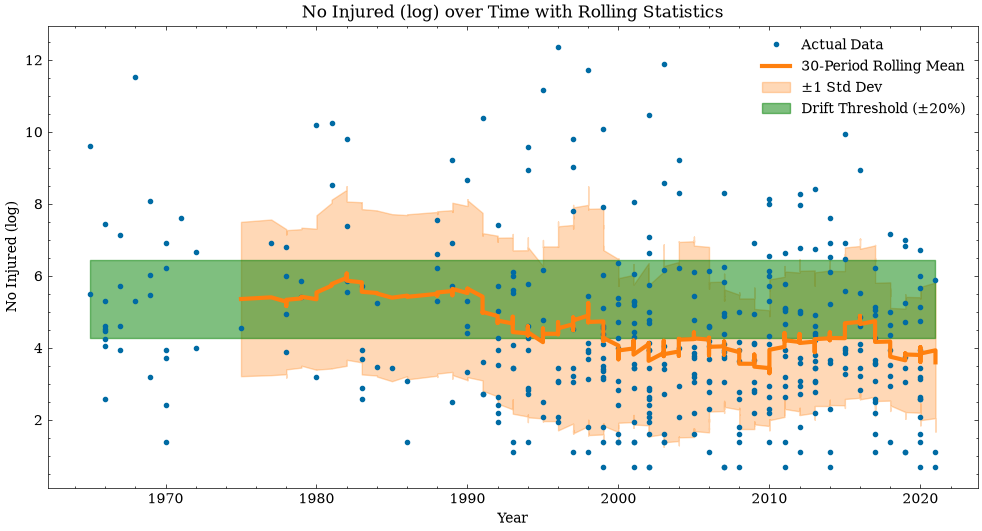

In [6]:
# (2.) Plot the data with rolling statistics
plt.figure(figsize=(12, 6))
# x: Year, y: true number of injured (log)
plt.plot(df_model["Year"], df_model[feature_col], marker='o', markersize=3, linestyle='', label='Actual Data', color=defined_colors[0])

# ---- YOUR CODE GOES HERE (START) ---
# x: Year, y: rolling mean with std deviation shading
plt.plot(df_model["Year"], rolling_mean, color=defined_colors[1], linestyle='-', 
     linewidth=3, label=f'{window_size}-Period Rolling Mean')
# fill between rolling mean ± std deviation
plt.fill_between(df_model["Year"], rolling_mean - rolling_std, 
         rolling_mean + rolling_std, color=defined_colors[1], alpha=0.3, 
         label='±1 Std Dev')
# --- YOUR CODE GOES HERE (END) ---

# (3.) Add drift detection thresholds
THRESHOLD_PERCENT = 0.20  
first_valid_idx = rolling_mean.first_valid_index()

# ---- YOUR CODE GOES HERE (START) ---
# calculate and plot drift detection thresholds based on the first valid rolling mean value
if first_valid_idx is not None:
  # get the first valid rolling mean value
  first_rolling_mean = rolling_mean.loc[first_valid_idx]
  # calculate upper and lower thresholds of ±20%
  drift_upper_threshold = first_rolling_mean * (1 + THRESHOLD_PERCENT)
  drift_lower_threshold = first_rolling_mean * (1 - THRESHOLD_PERCENT)
  # print the thresholds
  print(f"Drift Detection Thresholds: Upper = {drift_upper_threshold:.4f}, Lower = {drift_lower_threshold:.4f}")
  # plot the thresholds as filled areas
  plt.fill_between(df_model["Year"], drift_lower_threshold, drift_upper_threshold, 
           color='green', alpha=0.5, label='Drift Threshold (±20%)')
# --- YOUR CODE GOES HERE (END) ---

# plot formatting
plt.title(f"{feature_col} over Time with Rolling Statistics")
plt.xlabel("Year")
plt.ylabel(feature_col)
plt.legend()
plt.grid()
plt.show()

## **TASK: Two-Sample Statistical Test for Drift Detection**

Before, we set an arbitrary threshold at which we label deviation from the base values as drifts. Now, we apply a more precise measure to indicate drifts in the form of a **two-sample statistical test**.  
The idea is to compare two subsets of data — a **reference window** (past observations) and a **test window** (new observations) — to evaluate whether their distributions differ significantly.

We use the **Kolmogorov–Smirnov (KS) test**, a non-parametric test that measures the largest distance between the cumulative distributions of two samples.  
- A **high p-value** means distributions are similar (no drift detected).  
- A **low p-value** means distributions differ significantly (possible drift).

Apply Kolmogorov-Smirnov test to detect distribution shifts using sliding windows.
Compare a reference window with subsequent test windows to identify when the distribution changes significantly.
You can find the documentation on the KS test [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html).

Complete the following steps by replacing the ``None`` placeholders with the correct values and variables:
1. Within a loop, extract test windows from the dataset
2. Apply the KS test between the reference window and each test window and record p-values 
3. Visualize the significance level and detected drifts

In [7]:
from scipy import stats

feature_col = "No Injured (log)" 
REFERENCE_SIZE = 10  # Number of observations in reference window
TEST_SIZE = 10 # Number of observations in test window
ALPHA = 0.1  # Significance level

# Prepare reference data (of first 10 observations) and storage for test results
ref_data = df_model[feature_col].iloc[:REFERENCE_SIZE].values
test_results = []

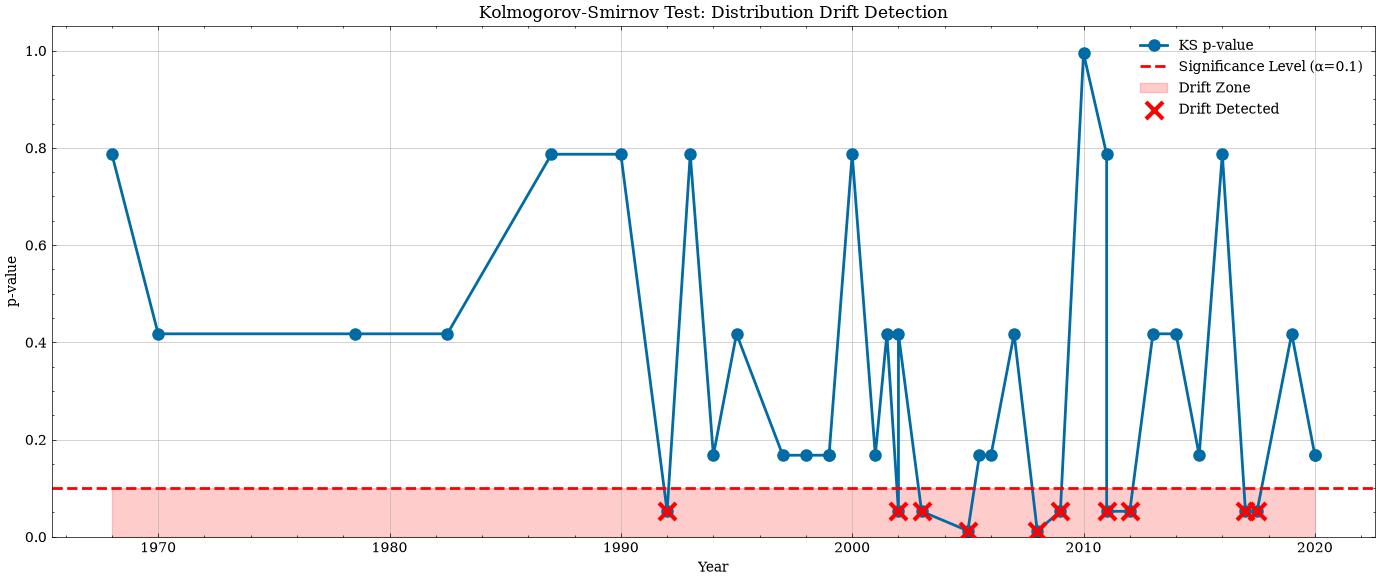

In [8]:
# Iterate over the dataset in steps of TEST_SIZE
for i in range(REFERENCE_SIZE + TEST_SIZE, len(df_model), TEST_SIZE):
  # Define the start and end indices for the test window
  test_start = i - TEST_SIZE
  test_end = i
    
  # (1.) Extract test window data

  # ---- YOUR CODE GOES HERE (START) ---
  # Extract test window data from test_start to test_end
  test_data = df_model[feature_col].iloc[test_start:test_end].values
  # --- YOUR CODE GOES HERE (END) ---
    
  # Ensure we have enough data points in the test window
  if len(test_data) < TEST_SIZE:
    continue

  # (2.) Apply KS test and record results

  # ---- YOUR CODE GOES HERE (START) ---
  # Perform the Kolmogorov-Smirnov test
  ks_statistic, ks_pvalue = stats.ks_2samp(ref_data, test_data)
  # Determine if drift is detected based on p-value
  drift_detected = ks_pvalue < ALPHA
  # Calculate the median year for the test window
  test_year = df_model.iloc[test_start:test_end]["Year"].median()
    
  # Store the results
  test_results.append({
    'Year': test_year,
    'Window_Start': df_model.iloc[test_start]["Year"],
    'Window_End': df_model.iloc[test_end-1]["Year"],
    'KS_Statistic': ks_statistic,
    'KS_PValue': ks_pvalue,
    'Drift_Detected': drift_detected
  })
  # --- YOUR CODE GOES HERE (END) ---

# Plot the results of the KS test
results_df = pd.DataFrame(test_results)
# x: Year, y: KS p-value
plt.plot(results_df['Year'], results_df['KS_PValue'], linewidth=2, 
       marker='o', markersize=8, color=defined_colors[0], label='KS p-value')

# (3.) Visualize the significance level and detected drifts
# ---- YOUR CODE GOES HERE (START) ---
# plot significance level line and highlight drift detections
plt.axhline(y=ALPHA, color='red', linestyle='--', linewidth=2, 
        label=f'Significance Level (α={ALPHA})')
# fill area below significance level
plt.fill_between(results_df['Year'], 0, ALPHA, alpha=0.2, color='red', 
            label='Drift Zone')
# highlight points where drift was detected
drift_points = results_df[results_df['Drift_Detected'] == True]
if len(drift_points) > 0:
  plt.scatter(drift_points['Year'], drift_points['KS_PValue'], 
          color='red', s=150, marker='x', linewidth=3, 
          label='Drift Detected', zorder=5)
# --- YOUR CODE GOES HERE (END) ---

# plot formatting
plt.xlabel('Year')
plt.ylabel('p-value')
plt.title('Kolmogorov-Smirnov Test: Distribution Drift Detection')
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()